## Daily Chain Mode and Weather Structure (Flag 25)

### Dataset Overview
An independently constructed, road-aligned WorldTrace case containing 168 trajectories.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Analyze how the user's trips are organized across the day and identify variations in daily travel structure.

Role: Mobility-pattern analyst


Category: Daily trip chains, mode allocation, weather, temperature, and route replacement

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectories.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How many active days form multi-trip chains that return near their starting area?

#### Analysis action

Group trajectories by service date, order their segments, and compare daily start and end positions.

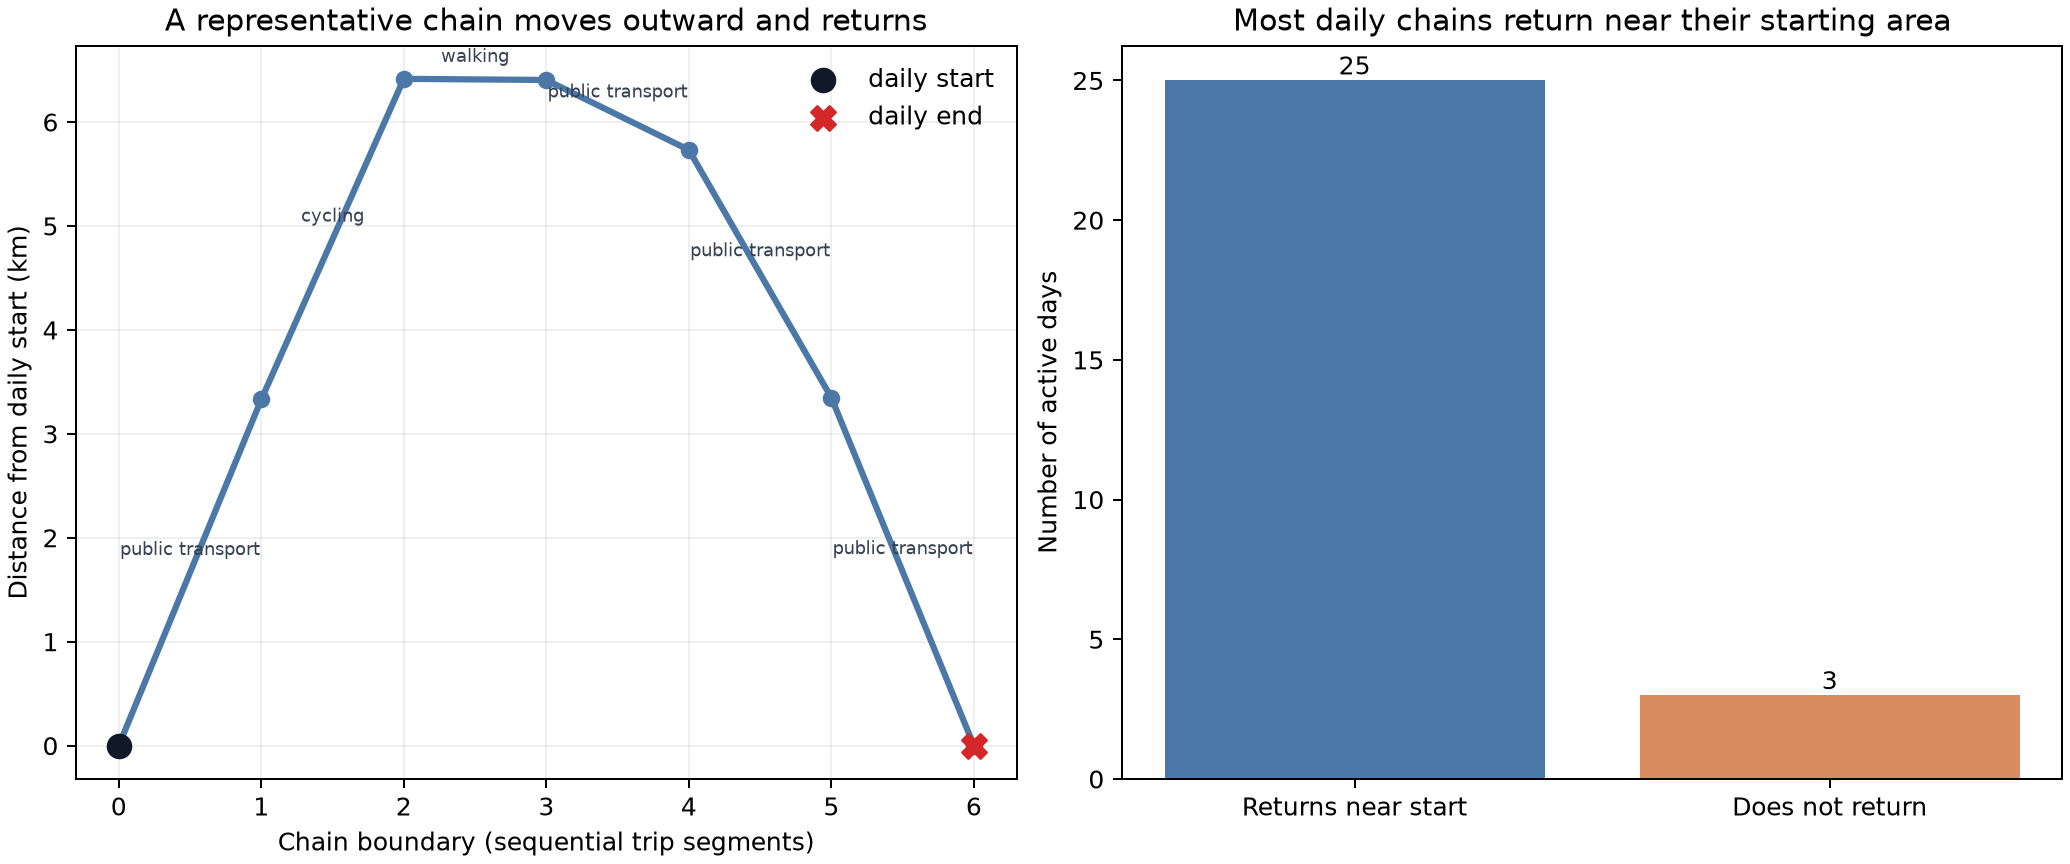

In [ ]:
print(df.groupby('service_date').first()[['segments_in_day','daily_return_distance_m','day_returns_near_start']])
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/insight_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex25_insight_1",
  "insight": "Most active days form multi-trip chains that eventually return near the day's starting area.",
  "plot": {
    "plot_type": "question_specific_summary",
    "title": "Daily Chain Mode and Weather Structure: Insight 1",
    "description": "Question-specific evidence computed from the synchronized trajectory and point tables; the case-level route overview is retained separately.",
    "file": "visualizations/insight_1.png"
  },
  "question": "How many active days form multi-trip chains that return near their starting area?",
  "actionable_insight": "Group trajectories by service date, order their segments, and compare daily start and end positions.",
  "code": "print(df.groupby('service_date').first()[['segments_in_day','daily_return_distance_m','day_returns_near_start']])",
  "insight_type": "overall_pattern",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "trajectory_id",
    "gps_position",
    "user_id",
    "transport_mode"
  ]
}

### **Question 2**: Which modes account for weekday travel, especially at the first and last chain positions?

#### Analysis action

Compute distance-weighted mode shares for all weekday trips and by chain position.

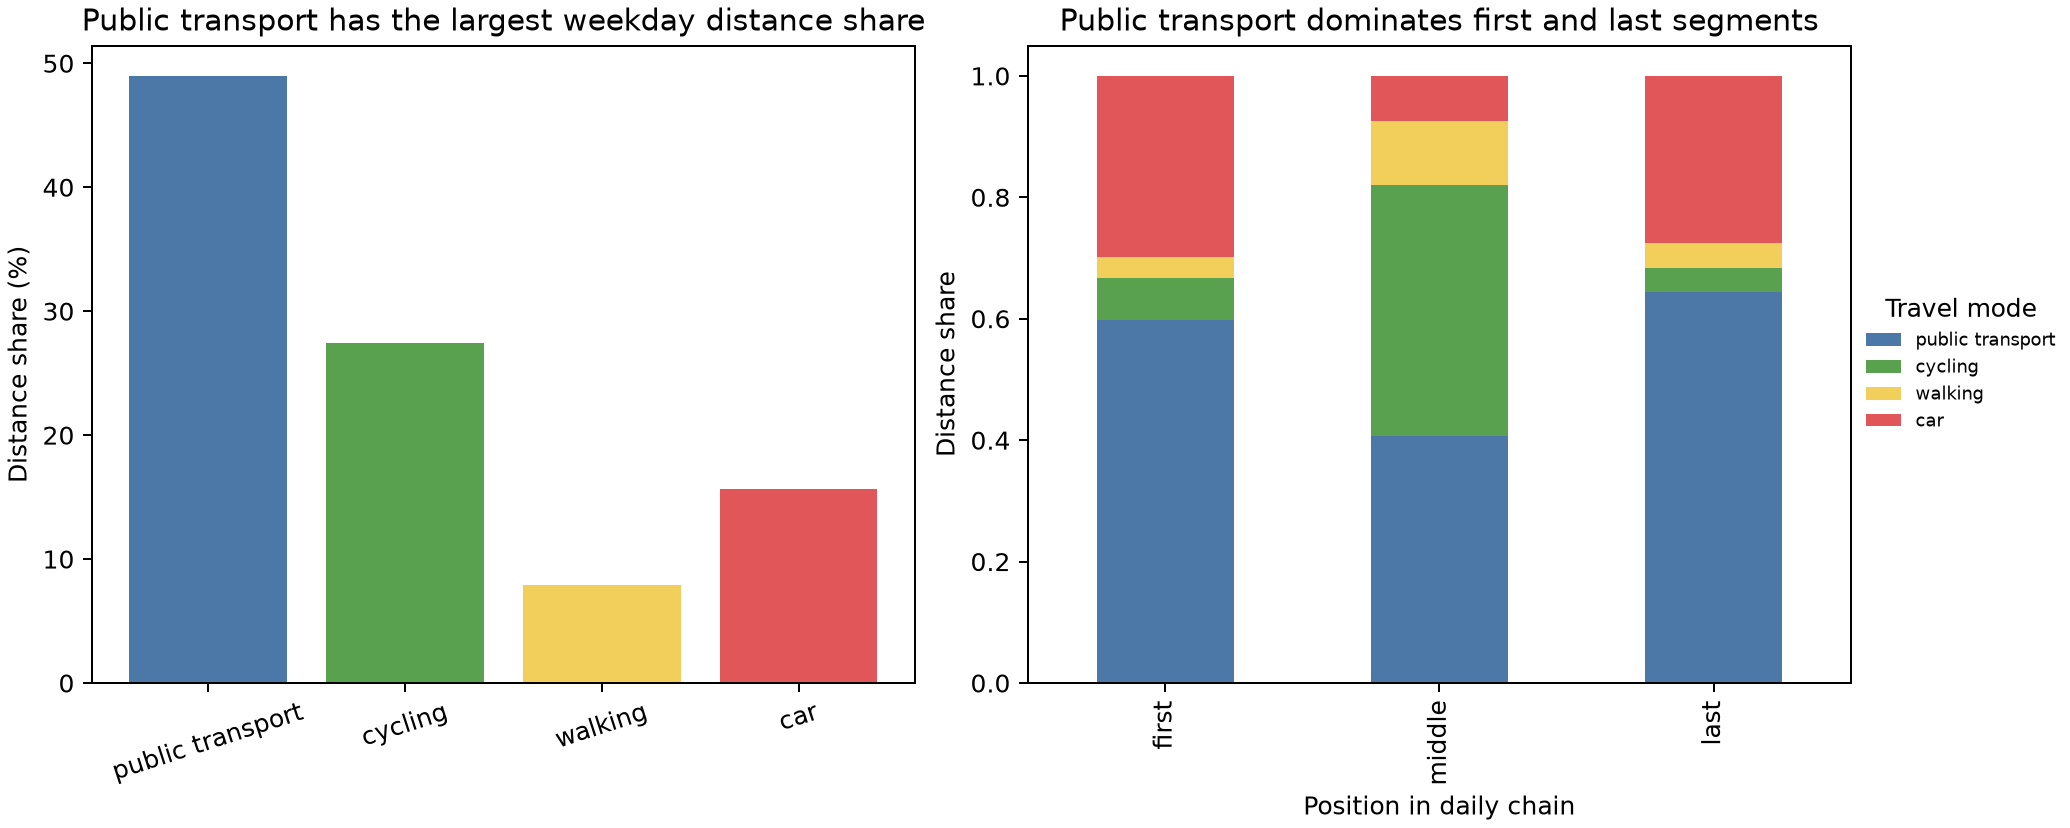

In [ ]:
q=df[df.day_type.eq('weekday')]; print(q.groupby('travel_mode').trajectory_distance_km.sum()/q.trajectory_distance_km.sum()); print(q.groupby(['chain_position','travel_mode']).trajectory_distance_km.sum().unstack(fill_value=0))
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/insight_2.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex25_insight_2",
  "insight": "Public transport takes the largest share of trips on weekdays, especially for first and last segments of one day's multi-trip chain.",
  "plot": {
    "plot_type": "question_specific_summary",
    "title": "Daily Chain Mode and Weather Structure: Insight 2",
    "description": "Question-specific evidence computed from the synchronized trajectory and point tables; the case-level route overview is retained separately.",
    "file": "visualizations/insight_2.png"
  },
  "question": "Which modes account for weekday travel, especially at the first and last chain positions?",
  "actionable_insight": "Compute distance-weighted mode shares for all weekday trips and by chain position.",
  "code": "q=df[df.day_type.eq('weekday')]; print(q.groupby('travel_mode').trajectory_distance_km.sum()/q.trajectory_distance_km.sum()); print(q.groupby(['chain_position','travel_mode']).trajectory_distance_km.sum().unstack(fill_value=0))",
  "insight_type": "overall_pattern",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "trajectory_id",
    "transport_mode",
    "matched_road_position",
    "user_id"
  ]
}

### **Question 3**: Under which conditions do car trips occur, and do they occupy usual public-transport route slots?

#### Analysis action

Track public-transport and car shares on the same route slots across rainfall intensities, and inspect temperature-linked replacement on a fixed route template.

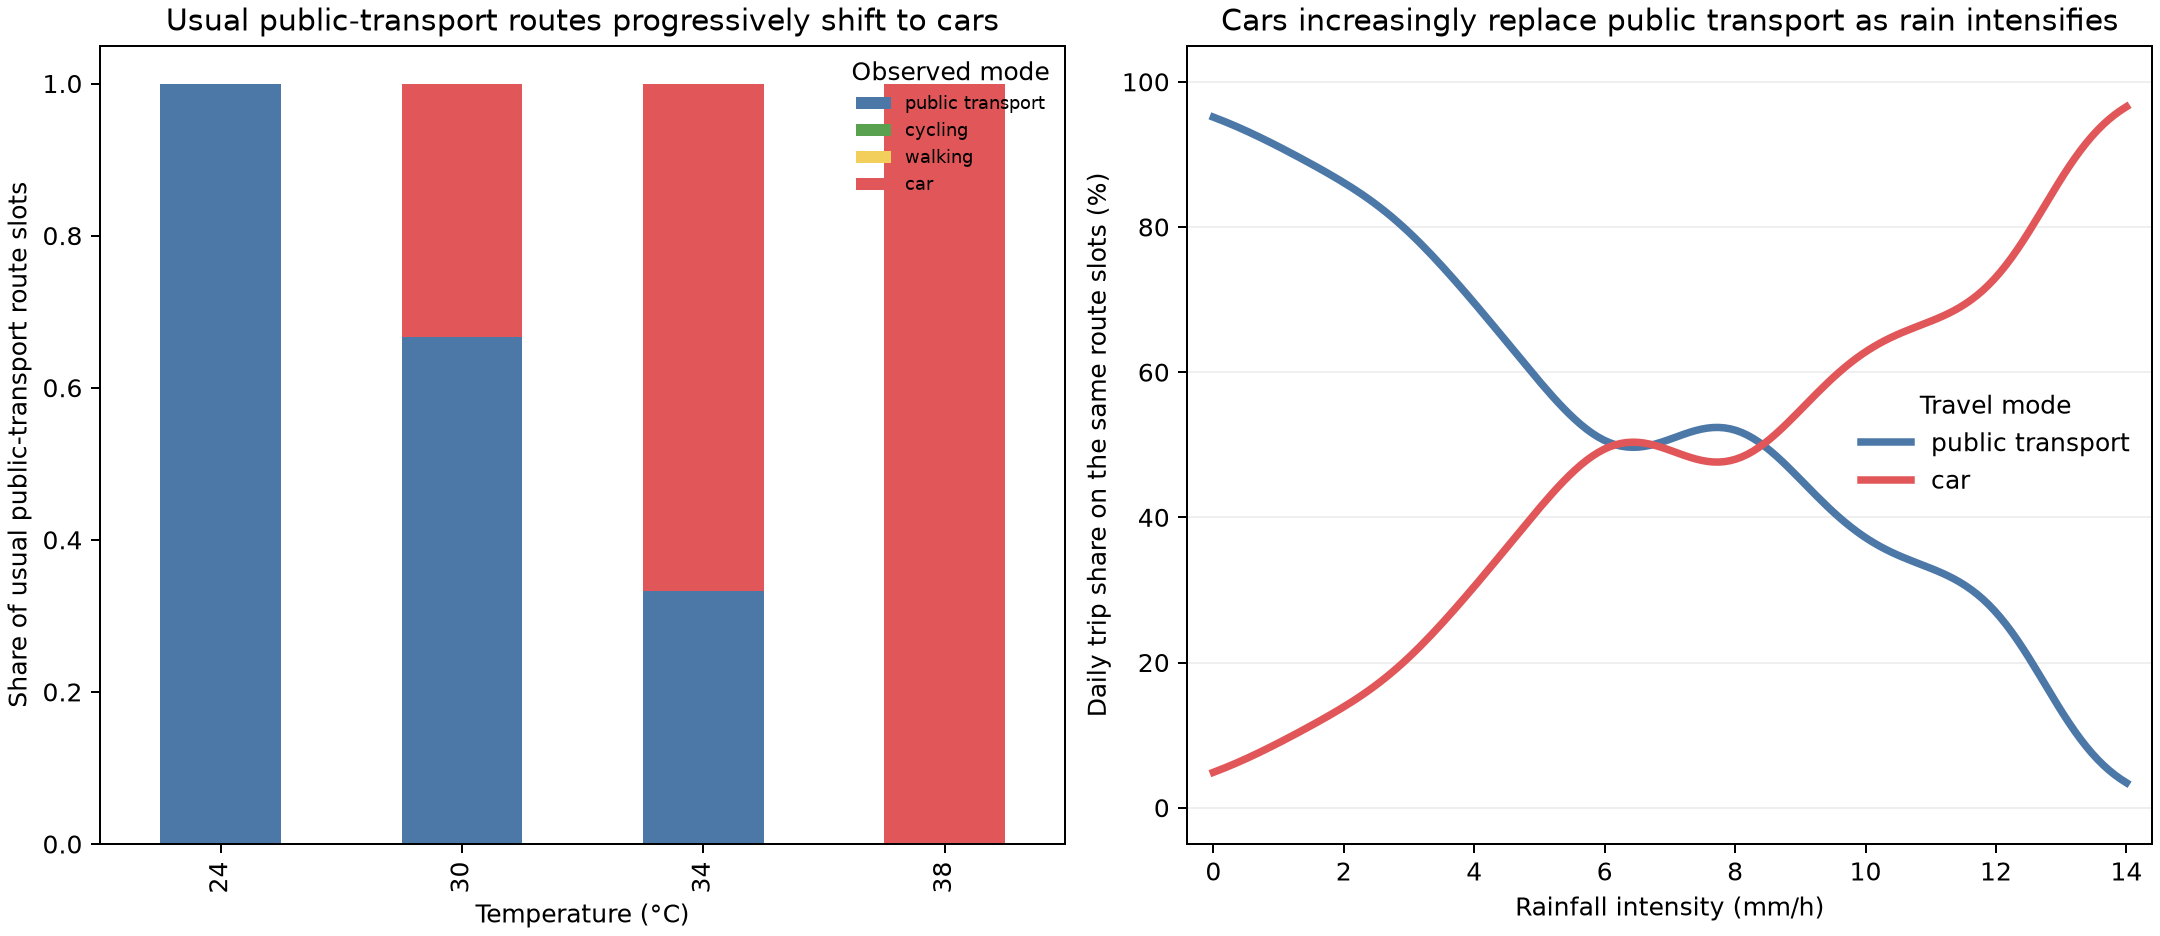

In [ ]:
w=df[df.day_type.eq('weekday')]; q=w[w.usual_public_transport_segment & w.chain_template.isin(['template_1','template_2','template_3'])]; print(q.groupby(['service_date','rainfall_mm_h','travel_mode']).size().unstack(fill_value=0)); print(w[w.usual_public_transport_segment & w.chain_template.eq('template_4')].groupby(['temperature_c','travel_mode']).size().unstack(fill_value=0))
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/insight_3.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex25_insight_3",
  "insight": "Car trips are always accompanied by rain or hot weather and replace public transport trips on weekdays.",
  "plot": {
    "plot_type": "question_specific_summary",
    "title": "Daily Chain Mode and Weather Structure: Insight 3",
    "description": "Question-specific evidence computed from the synchronized trajectory and point tables; the case-level route overview is retained separately.",
    "file": "visualizations/insight_3.png"
  },
  "question": "Under which conditions do car trips occur, and do they occupy usual public-transport route slots?",
  "actionable_insight": "Track public-transport and car shares on the same route slots across rainfall intensities, and inspect temperature-linked replacement on a fixed route template.",
  "code": "w=df[df.day_type.eq('weekday')]; q=w[w.usual_public_transport_segment & w.chain_template.isin(['template_1','template_2','template_3'])]; print(q.groupby(['service_date','rainfall_mm_h','travel_mode']).size().unstack(fill_value=0)); print(w[w.usual_public_transport_segment & w.chain_template.eq('template_4')].groupby(['temperature_c','travel_mode']).size().unstack(fill_value=0))",
  "insight_type": "exception_deviation",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "trajectory_id",
    "gps_position",
    "transport_mode",
    "rainfall",
    "temperature"
  ]
}

### Summary of Findings (Flag 25)

Most active days form multi-trip chains that eventually return near the day's starting area. Public transport takes the largest share of trips on weekdays, especially for first and last segments of one day's multi-trip chain. Car trips are always accompanied by rain or hot weather and replace public transport trips on weekdays.